# IE7615 Milestone 2: Conditional Generation, Guidance and Noise Schedule Tuning

Goals:
1. Integrate the CLIP text encoder with Stable Diffusion v1.5
2. Run baseline conditional generation
3. Tune classifier free guidance (CFG) and the noise schedule (sampler, noise level spacing and number of steps)
4. Record the first set of generated images and an experiment log

Every setting is tested on 5 Flickr30k captions with 3 seeds each, so the comparisons do not depend on one lucky image.

Runtime: Google Colab with a T4 GPU (Runtime > Change runtime type > T4 GPU). The full run makes about 210 images and takes roughly 20 to 25 minutes.

## 1. Setup

In [1]:
!pip install -q diffusers transformers accelerate pandas matplotlib

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import time, shutil
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

project_dir = Path("/content/drive/MyDrive/IE7615_Project")
out_dir = project_dir / "milestone2_outputs"
img_dir = out_dir / "images"
img_dir.mkdir(parents=True, exist_ok=True)

device = "cuda"
SEEDS = [42, 7, 123]
print("GPU:", torch.cuda.get_device_name(0))
print("Output folder:", out_dir)

Mounted at /content/drive
GPU: Tesla T4
Output folder: /content/drive/MyDrive/IE7615_Project/milestone2_outputs


## 2. Load Stable Diffusion v1.5 and its CLIP text encoder

The original runwayml repository was taken down from Hugging Face, so we fall back to the official mirror if it is not available.

In [3]:
from diffusers import StableDiffusionPipeline

def load_pipeline():
    for model_id in ["runwayml/stable-diffusion-v1-5", "stable-diffusion-v1-5/stable-diffusion-v1-5"]:
        try:
            p = StableDiffusionPipeline.from_pretrained(model_id, dtype=torch.float16, safety_checker=None)
            print("Loaded:", model_id)
            return p
        except Exception as e:
            print(f"Could not load {model_id}: {type(e).__name__}")
    raise RuntimeError("Stable Diffusion v1.5 could not be loaded")

pipe = load_pipeline().to(device)
pipe.set_progress_bar_config(disable=True)
default_config = pipe.scheduler.config

print("Text encoder:", pipe.text_encoder.config._name_or_path, "| hidden size:", pipe.text_encoder.config.hidden_size)
print("UNet cross attention dim:", pipe.unet.config.cross_attention_dim)
print("Default scheduler:", pipe.scheduler.__class__.__name__, "| beta schedule:", default_config.beta_schedule)

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loaded: runwayml/stable-diffusion-v1-5
Text encoder: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder | hidden size: 768
UNet cross attention dim: 768
Default scheduler: PNDMScheduler | beta schedule: scaled_linear


## 3. Integrate the text encoder with the diffusion model

We encode each prompt ourselves with the CLIP ViT-L/14 text encoder and pass the embeddings (`prompt_embeds`) to the UNet, which reads them through cross attention at every denoising step. The empty prompt embedding is the unconditional branch that classifier free guidance compares against.

As a check, our embeddings should match what the pipeline produces internally from the same text.

In [4]:
@torch.no_grad()
def encode_text(texts):
    tokens = pipe.tokenizer(texts, padding="max_length", max_length=pipe.tokenizer.model_max_length,
                            truncation=True, return_tensors="pt").to(device)
    return pipe.text_encoder(tokens.input_ids)[0]

test_prompt = "a dog running through a green field"
cond = encode_text([test_prompt])
uncond = encode_text([""])
print("Conditional embedding:", tuple(cond.shape))
print("Unconditional embedding:", tuple(uncond.shape))

pipe_cond, pipe_uncond = pipe.encode_prompt(test_prompt, device, 1, True, negative_prompt="")
print("Matches the pipeline's own encoding:",
      torch.allclose(cond, pipe_cond, atol=1e-3) and torch.allclose(uncond, pipe_uncond, atol=1e-3))

Conditional embedding: (1, 77, 768)
Unconditional embedding: (1, 77, 768)
Matches the pipeline's own encoding: True


## 4. CLIP score, generation helper and experiment log

Each image gets a CLIP score: the cosine similarity between the image and its prompt, times 100, measured with CLIP ViT-B/32 (the model from Milestone 1). Using a different CLIP model from the one inside Stable Diffusion keeps the score from simply rewarding the generator's own encoder. Higher means a closer match to the text.

Identical settings are generated once and reused, and the log is saved after every experiment so a disconnect does not lose the results.

In [5]:
from transformers import CLIPModel, CLIPProcessor
from diffusers import PNDMScheduler, DDIMScheduler, EulerDiscreteScheduler, DPMSolverMultistepScheduler

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def clip_score(image, prompt):
    inputs = clip_proc(text=[prompt], images=image, return_tensors="pt",
                       padding=True, truncation=True, max_length=77).to(device)
    out = clip_model(**inputs)
    img = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    txt = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return round(float((img * txt).sum()) * 100, 2)

SCHEDULERS = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "DPM++": DPMSolverMultistepScheduler,
}

def set_scheduler(name, karras=False):
    extra = {"use_karras_sigmas": True} if karras else {}
    pipe.scheduler = SCHEDULERS[name].from_config(default_config, **extra)

log, cache = [], {}

def generate(prompt_id, prompt, experiment, guidance=7.5, steps=30, scheduler="PNDM", karras=False, seed=42):
    key = (prompt, scheduler, karras, steps, guidance, seed)
    if key in cache:
        row = dict(cache[key], experiment=experiment)
        log.append(row)
        return Image.open(img_dir / row["image_file"])

    set_scheduler(scheduler, karras)
    cond, uncond = encode_text([prompt]), encode_text([""])
    g = torch.Generator(device).manual_seed(seed)
    torch.cuda.synchronize(); t0 = time.time()
    image = pipe(prompt_embeds=cond, negative_prompt_embeds=uncond, guidance_scale=guidance,
                 num_inference_steps=steps, generator=g).images[0]
    torch.cuda.synchronize(); secs = round(time.time() - t0, 2)

    sched_label = scheduler + (" Karras" if karras else "")
    fname = f"p{prompt_id}_{sched_label.replace(' ', '_').replace('+', 'p')}_s{steps}_cfg{guidance}_seed{seed}.png"
    image.save(img_dir / fname)
    row = dict(experiment=experiment, prompt_id=prompt_id, prompt=prompt, scheduler=sched_label,
               steps=steps, guidance=guidance, seed=seed, seconds=secs,
               clip_score=clip_score(image, prompt), image_file=fname)
    cache[key] = row
    log.append(row)
    return image

def run(experiment, settings):
    for setting in settings:
        for pid, prompt in enumerate(prompts):
            for seed in SEEDS:
                generate(pid, prompt, experiment, seed=seed, **setting)
    pd.DataFrame(log).to_csv(out_dir / "experiment_log.csv", index=False)

def summarize(experiment, by):
    df = pd.DataFrame(log)
    df = df[df.experiment == experiment]
    return (df.groupby(by, sort=False)
              .agg(clip_mean=("clip_score", "mean"), clip_std=("clip_score", "std"),
                   seconds=("seconds", "mean"), images=("clip_score", "size"))
              .round(2))

def show_grid(experiment, column, labels, prompt_ids=(0, 1), seed=42):
    df = pd.DataFrame(log)
    df = df[(df.experiment == experiment) & (df.seed == seed)]
    fig, axes = plt.subplots(len(prompt_ids), len(labels), figsize=(3.2 * len(labels), 3.5 * len(prompt_ids)))
    axes = np.atleast_2d(axes)
    for r, pid in enumerate(prompt_ids):
        for c, label in enumerate(labels):
            row = df[(df.prompt_id == pid) & (df[column] == label)].iloc[0]
            axes[r, c].imshow(Image.open(img_dir / row.image_file))
            axes[r, c].set_title(f"{label}\nCLIP {row.clip_score}", fontsize=10)
            axes[r, c].axis("off")
        axes[r, 0].text(-0.08, 0.5, prompts[pid][:40], transform=axes[r, 0].transAxes,
                        rotation=90, va="center", ha="right", fontsize=9)
    plt.tight_layout()
    plt.savefig(out_dir / f"grid_{experiment}.png", dpi=110)
    plt.show()

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## 5. Prompts and warm up

Five captions from our cleaned Flickr30k subset. One throwaway image is generated first so that model loading time does not inflate the timing of the first logged run.

In [6]:
df_captions = pd.read_csv(project_dir / "captions_clean.csv")
prompts = df_captions["caption"].sample(5, random_state=7).tolist()
for i, p in enumerate(prompts):
    print(i, p)

set_scheduler("PNDM")
_ = pipe("warm up", num_inference_steps=5, guidance_scale=7.5)

0 a female wearing a black shirt and dark blue pants is practicing gymnastics on a beam , performing a handstnad split that exposes her bellybutton .
1 a man in a military-type uniform is standing in the street listening to another man who has a piece of paper in his hands .
2 a man wearing a reflective vest sits on the sidewalk and holds up pamphlets with bicycles on the cover .
3 a man in a black shirt shares something with a group of girls sitting on a bench .
4 a man in a blue jacket holding a handsaw sawing a pipe on top of a wood fence .


## 6. Baseline conditional generation

Default settings: PNDM scheduler, 30 steps, CFG 7.5, seeds 42, 7 and 123.

,clip_mean,clip_std,seconds,images
prompt_id,,,,
0,31.96,1.00,4.57,3
1,32.46,2.11,4.69,3
2,31.32,1.49,4.84,3
3,32.99,1.30,5.04,3
4,32.78,3.18,5.21,3


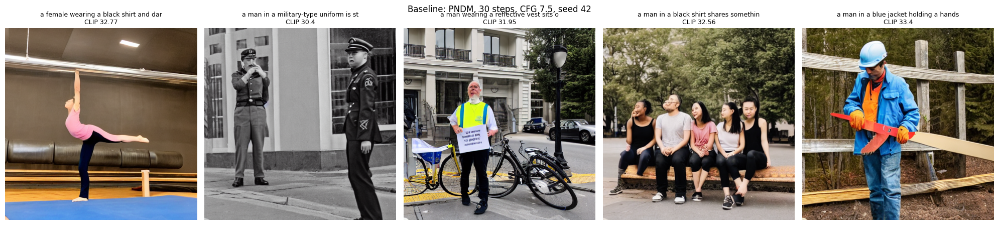

In [7]:
run("baseline", [dict()])
display(summarize("baseline", "prompt_id"))

df = pd.DataFrame(log)
base = df[(df.experiment == "baseline") & (df.seed == 42)]
fig, axes = plt.subplots(1, len(prompts), figsize=(4 * len(prompts), 4.6))
for ax, (_, r) in zip(axes, base.iterrows()):
    ax.imshow(Image.open(img_dir / r.image_file))
    ax.set_title(f"{r.prompt[:38]}\nCLIP {r.clip_score}", fontsize=9)
    ax.axis("off")
plt.suptitle("Baseline: PNDM, 30 steps, CFG 7.5, seed 42")
plt.tight_layout(); plt.savefig(out_dir / "grid_baseline.png", dpi=110); plt.show()

## 7. Classifier free guidance sweep

At every step the model makes two noise predictions, one with the prompt and one without, and guidance pushes the result away from the unconditional one: `noise = uncond + scale x (cond - uncond)`. A scale of 1.0 means no guidance. Higher values follow the text more closely, but very high values tend to oversaturate the image.

,clip_mean,clip_std,seconds,images
guidance,,,,
1.0,26.31,3.43,3.39,15
3.0,30.22,2.43,5.93,15
5.0,32.05,1.57,5.88,15
7.5,32.30,1.78,4.87,15
10.0,33.11,2.00,5.87,15
15.0,32.54,2.13,5.89,15


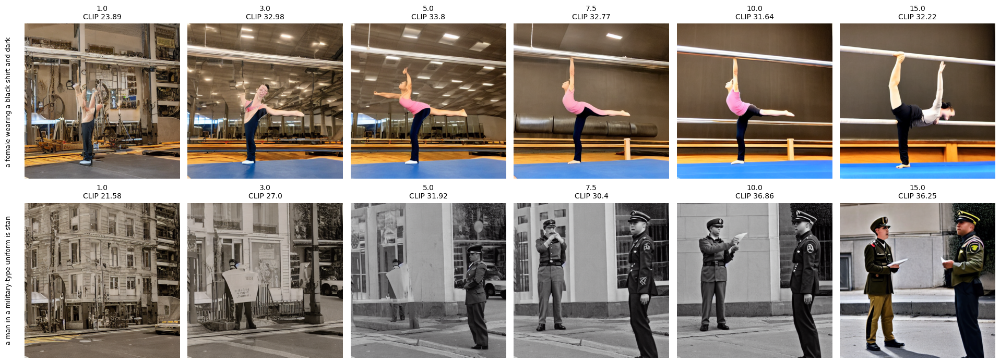

In [8]:
CFG_VALUES = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]
run("cfg", [dict(guidance=g) for g in CFG_VALUES])
cfg_table = summarize("cfg", "guidance")
display(cfg_table)
show_grid("cfg", "guidance", CFG_VALUES)

## 8. Noise schedule

Stable Diffusion was trained with a fixed scaled linear beta schedule. At sampling time we can still change how the model walks back from noise to an image:

* **Sampler:** PNDM, DDIM, Euler and DPM++ use different update rules for each denoising step.
* **Noise level spacing:** Karras sigmas place more of the steps at low noise levels, where fine detail is formed.
* **Number of steps:** fewer steps are faster but can leave the image unfinished.

### 8a. Sampler and noise level spacing (30 steps, CFG 7.5)

,clip_mean,clip_std,seconds,images
scheduler,,,,
PNDM,32.30,1.78,4.87,15
DDIM,32.61,2.31,5.71,15
Euler,32.68,2.38,5.71,15
Euler Karras,32.68,2.54,5.69,15
DPM++,33.30,2.54,5.72,15
DPM++ Karras,33.19,2.23,5.70,15


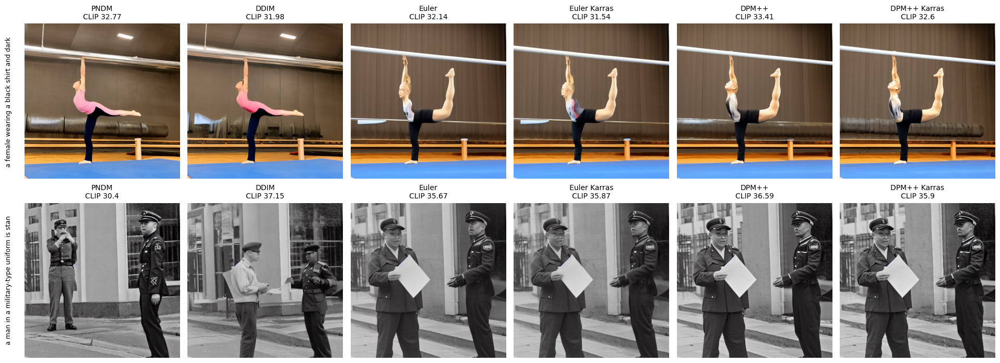

Best sampler by mean CLIP score: DPM++


In [9]:
SCHEDULER_SETTINGS = [
    dict(scheduler="PNDM"),
    dict(scheduler="DDIM"),
    dict(scheduler="Euler"),
    dict(scheduler="Euler", karras=True),
    dict(scheduler="DPM++"),
    dict(scheduler="DPM++", karras=True),
]
run("scheduler", SCHEDULER_SETTINGS)
sched_table = summarize("scheduler", "scheduler")
display(sched_table)
show_grid("scheduler", "scheduler", list(sched_table.index))

best_label = sched_table.sort_values(["clip_mean", "seconds"], ascending=[False, True]).index[0]
best_sched = dict(scheduler=best_label.replace(" Karras", ""), karras=best_label.endswith("Karras"))
print("Best sampler by mean CLIP score:", best_label)

### 8b. Number of steps with the best sampler

,clip_mean,clip_std,seconds,images
steps,,,,
10,33.02,2.56,2.07,15
20,33.36,2.43,3.88,15
30,33.30,2.54,5.72,15
50,32.94,2.00,9.35,15


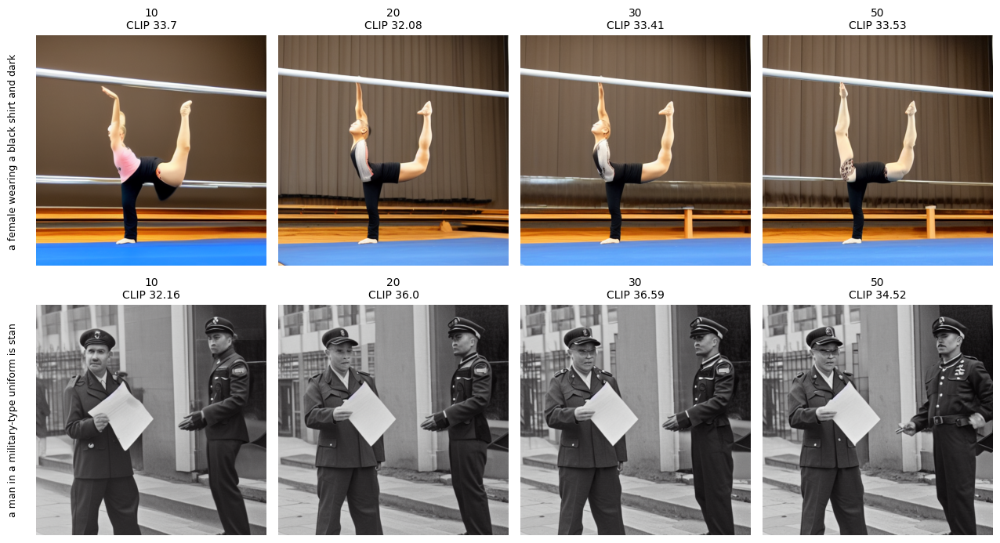

In [10]:
STEP_VALUES = [10, 20, 30, 50]
run("steps", [dict(steps=s, **best_sched) for s in STEP_VALUES])
steps_table = summarize("steps", "steps")
display(steps_table)
show_grid("steps", "steps", STEP_VALUES)

## 9. Experiment log and plots

Saved: /content/drive/MyDrive/IE7615_Project/milestone2_outputs/experiment_log.csv | 255 rows, 210 unique images


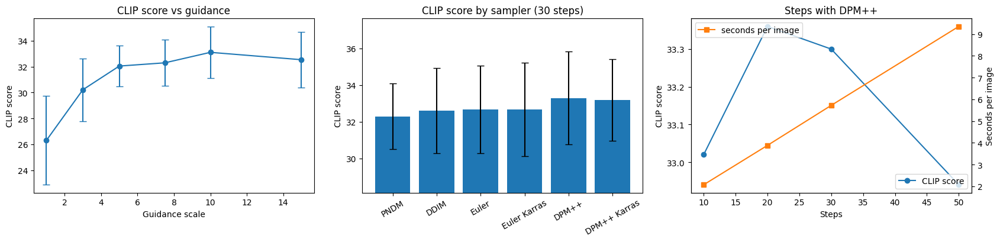

In [11]:
log_df = pd.DataFrame(log)
log_df.to_csv(out_dir / "experiment_log.csv", index=False)
print("Saved:", out_dir / "experiment_log.csv", "|", len(log_df), "rows,", log_df.image_file.nunique(), "unique images")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].errorbar(cfg_table.index, cfg_table.clip_mean, yerr=cfg_table.clip_std, marker="o", capsize=4)
axes[0].set_xlabel("Guidance scale"); axes[0].set_ylabel("CLIP score"); axes[0].set_title("CLIP score vs guidance")

axes[1].bar(sched_table.index, sched_table.clip_mean, yerr=sched_table.clip_std, capsize=4)
axes[1].set_ylabel("CLIP score"); axes[1].set_title("CLIP score by sampler (30 steps)")
axes[1].tick_params(axis="x", rotation=30)
lo = (sched_table.clip_mean - sched_table.clip_std).min()
axes[1].set_ylim(lo - 2, None)

axes[2].plot(steps_table.index, steps_table.clip_mean, marker="o", label="CLIP score")
axes[2].set_xlabel("Steps"); axes[2].set_ylabel("CLIP score"); axes[2].set_title(f"Steps with {best_label}")
ax_t = axes[2].twinx()
ax_t.plot(steps_table.index, steps_table.seconds, marker="s", color="tab:orange", label="seconds per image")
ax_t.set_ylabel("Seconds per image")
axes[2].legend(loc="lower right"); ax_t.legend(loc="upper left")

plt.tight_layout(); plt.savefig(out_dir / "metrics.png", dpi=120); plt.show()

## 10. Early samples

For each prompt we keep its two best images by CLIP score, giving 10 samples that cover all five prompts instead of ten versions of one.

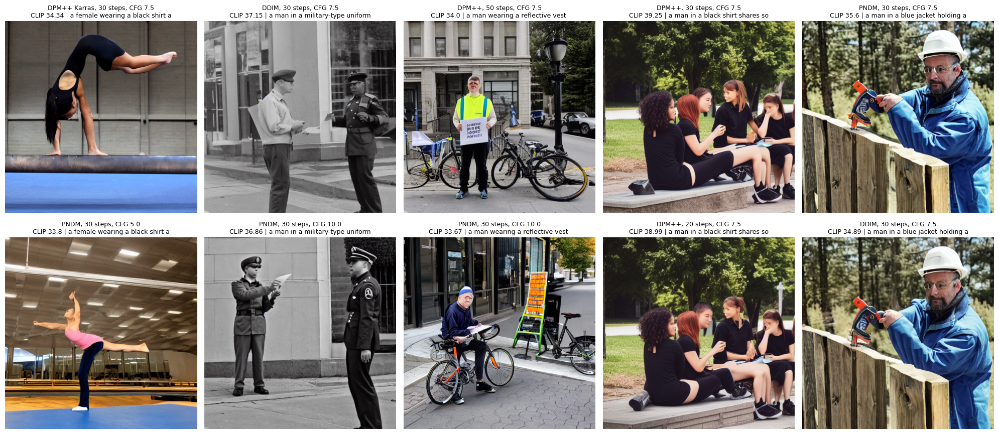

,prompt_id,prompt,scheduler,steps,guidance,seed,clip_score
182,0,a female wearing a black shirt and dark blue p...,DPM++ Karras,30,7.5,123,34.34
45,0,a female wearing a black shirt and dark blue p...,PNDM,30,5.0,42,33.80
123,1,a man in a military-type uniform is standing i...,DDIM,30,7.5,42,37.15
78,1,a man in a military-type uniform is standing i...,PNDM,30,10.0,42,36.86
246,2,a man wearing a reflective vest sits on the si...,DPM++,50,7.5,42,34.00
83,2,a man wearing a reflective vest sits on the si...,PNDM,30,10.0,123,33.67
176,3,a man in a black shirt shares something with a...,DPM++,30,7.5,123,39.25
221,3,a man in a black shirt shares something with a...,DPM++,20,7.5,123,38.99
13,4,a man in a blue jacket holding a handsaw sawin...,PNDM,30,7.5,7,35.60
133,4,a man in a blue jacket holding a handsaw sawin...,DDIM,30,7.5,7,34.89


In [12]:
unique = log_df.drop_duplicates("image_file")
best = (unique.sort_values("clip_score", ascending=False)
              .groupby("prompt_id", sort=False).head(2)
              .sort_values(["prompt_id", "clip_score"], ascending=[True, False]))
sample_dir = out_dir / "early_samples"
sample_dir.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for ax, (_, r) in zip(axes.T.flat, best.iterrows()):
    shutil.copy(img_dir / r.image_file, sample_dir / r.image_file)
    ax.imshow(Image.open(img_dir / r.image_file))
    ax.set_title(f"{r.scheduler}, {r.steps} steps, CFG {r.guidance}\nCLIP {r.clip_score} | {r.prompt[:32]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.savefig(out_dir / "early_samples_grid.png", dpi=110); plt.show()
best[["prompt_id", "prompt", "scheduler", "steps", "guidance", "seed", "clip_score"]]

## 11. Observations

**Text encoder integration.** Our own CLIP ViT-L/14 encoding gives a (1, 77, 768) embedding for both the prompt and the empty unconditional prompt, which matches the UNet's cross attention size of 768. It is identical to the pipeline's internal encoding of the same text, so the text conditioning is wired in correctly.

**Baseline (PNDM, 30 steps, CFG 7.5).** Mean CLIP scores range from 31.3 to 33.0 across the five prompts. The images are realistic and get the overall scene right, but they often miss the finer details of the long Flickr30k captions:
* the gymnast wears a pink top instead of a black shirt and is not on a beam
* the man in the reflective vest is standing and holding a sign, not sitting and holding pamphlets, and the bicycles from the pamphlet cover turn into real bicycles next to him
* the man with the handsaw holds a red tool, with no pipe being sawed
* in the bench scene, the girls are there but the man in the black shirt is not clearly shown

Stable Diffusion handles the main subject and setting well, but struggles with actions, small objects and which attribute belongs to which person.

**Guidance scale.** Guidance has by far the largest effect of anything we tested. Mean CLIP score rises from 26.31 at CFG 1.0 (no guidance) to 30.22 at 3.0, 32.05 at 5.0 and 32.30 at 7.5, peaks at 33.11 at 10.0, and drops slightly to 32.54 at 15.0. At CFG 1.0 the images barely follow the text, for example an empty street instead of two men talking. Higher guidance brings in more of the caption: the piece of paper appears from CFG 10, and the gymnast's black shirt only at CFG 15. Above 10, colors and contrast become noticeably stronger, which is the usual trade-off between following the text and looking natural. CFG 1.0 is also faster (3.4 seconds per image instead of 5 to 6), because it skips the unconditional prediction at every step.

**Sampler and noise level spacing.** At 30 steps the samplers differ by only 1 point: PNDM 32.30, DDIM 32.61, Euler 32.68, Euler Karras 32.68, DPM++ Karras 33.19 and DPM++ 33.30. That is smaller than the spread across seeds (about 2 to 2.5 points), so no sampler is clearly better at this step count. Karras sigmas made no measurable difference for either Euler or DPM++. With the same seed, the samplers mostly produce the same composition, with Euler and DPM++ giving almost identical images and PNDM and DDIM differing more in details such as clothing color.

**Number of steps (DPM++).** CLIP scores stay flat from 10 to 50 steps (33.02, 33.36, 33.30 and 32.94), while the time per image grows almost linearly (2.1, 3.9, 5.7 and 9.4 seconds). Visually, 10 steps gives softer and less detailed images, while 20 steps already looks as good as 30 or 50. 20 steps is the best trade-off: about a third faster than 30 steps and less than half the time of 50, with no loss in quality.

**Seeds.** Within each setting, CLIP scores vary by 1 to 3.4 points depending on the seed, which is as large as the differences between samplers or step counts. The best image for each prompt came from a mix of samplers, guidance values and seeds, so the starting noise matters as much as the settings, apart from guidance.

**Limits of the CLIP score.** The CLIP score rewards the overall match, not every detail. The bench scene got our highest score (39.25) even though the man from the caption is missing, and the baseline gymnast scored well despite the wrong shirt color. In Milestone 3 we will add FID and a closer look at prompt to image alignment.

**Best setting overall.** DPM++ with 20 steps and a guidance scale between 7.5 and 10. Guidance was tested with PNDM, so for Milestone 3 we will confirm this combination with DPM++ directly.